# Topological Accessibility of Hospitals & Clinics in Medellín
## Persistent Homology via Cubical Complexes

**Data source:** OpenStreetMap (Overpass API) – amenity=clinic, amenity=hospital, amenity=doctors, amenity=health_post

**Routing method:** Local Dijkstra on OSM pedestrian network (not Valhalla)


In [48]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.gridspec import GridSpec
import folium
from shapely.geometry import Point, Polygon
from shapely.ops import unary_union
import osmnx as ox
import networkx as nx
import requests
import json
import gudhi
from scipy.sparse.csgraph import dijkstra
from shapely.geometry import box, Point, Polygon

from scipy.spatial import cKDTree
import scipy.sparse as sp
from pathlib import Path
import time

print(f'NumPy   {np.__version__}')
print(f'GeoPandas {gpd.__version__}')
print(f'OSMnx   {ox.__version__}')
print(f'GUDHI   {gudhi.__version__}')
print('All imports OK ✓')

# Paths
PROJECT_ROOT = Path('/Users/gregorioperez/Documents/Maestria/Investigacion/urban_form/15_min_city_ph')
DATA_DIR = PROJECT_ROOT / 'data'
FIGS_DIR = PROJECT_ROOT / 'figs'
RESULTS_DIR = PROJECT_ROOT / 'results'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Constants
UTM_CRS = 'EPSG:32618'
WGS84 = 'EPSG:4326'
WALK_KMH = 4.7  # pedestrian speed in km/h (calibrated to match Valhalla)
WALK_M_PER_MIN = WALK_KMH * 1000.0 / 60.0
SENTINEL = 120.0  # unreachable cells
BBOX = (6.10, -75.70, 6.40, -75.44)  # Medellín

print(f'Walking speed: {WALK_KMH} km/h = {WALK_M_PER_MIN:.1f} m/min')

NumPy   1.26.4
GeoPandas 1.1.2
OSMnx   2.0.7
GUDHI   3.11.0
All imports OK ✓
Walking speed: 4.7 km/h = 78.3 m/min


In [49]:
def find_repo_root(start=Path.cwd()) -> Path:
    for candidate in [start.resolve(), *start.resolve().parents]:
        if (candidate / "graph_kernels").exists() and (candidate / "levelset_urban_ph").exists():
            return candidate
    raise FileNotFoundError(f"Could not find urban_form repository from {start.resolve()}")


In [50]:
# %%
# Use the exact same 100m grid from the malls analysis
cached_mall_parquet = '/Users/gregorioperez/Documents/Maestria/Investigacion/urban_form/15_min_city_ph/walking_time_mall.parquet'

grid = gpd.read_parquet(cached_mall_parquet)
grid = grid.to_crs(UTM_CRS)[['row_idx', 'col_idx', 'geometry']].copy()

# Centroid coords for routing
cen = grid.geometry.centroid
grid['centroid_utm'] = cen
centroids_wgs = gpd.GeoDataFrame(geometry=cen, crs=UTM_CRS).to_crs(WGS84).geometry
grid['centroid_lon'] = centroids_wgs.x
grid['centroid_lat'] = centroids_wgs.y

n_cols = int(grid.col_idx.max()) + 1
n_rows = int(grid.row_idx.max()) + 1
perim = grid.geometry.union_all()

print(f'Grid loaded:')
print(f'  Cells: {len(grid):,}')
print(f'  Dimensions: {n_rows} rows × {n_cols} cols')

Grid loaded:
  Cells: 13,150
  Dimensions: 149 rows × 130 cols


In [51]:
def fetch_hospitals_osm(
    bbox=BBOX,
    tags=None,
    retries=3,
    delay=10
):
    """Query Overpass API for hospitals and clinics."""

    if tags is None:
        tags = [
            "amenity=clinic",
            "amenity=doctors",
            "amenity=health_post",
            "amenity=hospital",
        ]

    south, west, north, east = bbox

    query = "[out:json][timeout:180];("
    for tag in tags:
        key, value = tag.split("=", maxsplit=1)
        query += (
            f'nwr["{key}"="{value}"]'
            f"({south},{west},{north},{east});"
        )
    query += ");out center tags;"

    url = "https://overpass-api.de/api/interpreter"

    headers = {
        # Replace the email with your real contact information
        "User-Agent": "UrbanHospitalResearch/1.0 (contact: greg2222@gmail.com)",
        "Accept": "application/json",
    }

    for attempt in range(retries):
        try:
            print(f"[{attempt + 1}/{retries}] Querying Overpass API...")

            response = requests.post(
                url,
                data={"data": query},
                headers=headers,
                timeout=300,
            )

            # Print Overpass's explanation before raising the exception
            if not response.ok:
                print(f"HTTP {response.status_code}")
                print(response.text[:1000])

            response.raise_for_status()

            result = response.json()
            return result.get("elements", [])

        except requests.exceptions.RequestException as error:
            if attempt < retries - 1:
                print(f"Attempt {attempt + 1} failed: {error}")
                time.sleep(delay)
            else:
                raise


# Try cache first

elements = fetch_hospitals_osm()

print(f'Raw Overpass elements: {len(elements)}')

[1/3] Querying Overpass API...
Raw Overpass elements: 270


In [52]:
recs = []
for e in elements:
    lon = e.get('lon', (e.get('center') or {}).get('lon'))
    lat = e.get('lat', (e.get('center') or {}).get('lat'))
    if lon is None or lat is None:
        continue
    tags = e.get('tags') or {}
    recs.append({
        'osm_id': f"{e['type']}/{e['id']}",
        'name': tags.get('name'),
        'amenity': tags.get('amenity'),
        'lon': lon,
        'lat': lat
    })

df = pd.DataFrame(recs).drop_duplicates('osm_id')
hospitals_gdf = gpd.GeoDataFrame(
    df,
    geometry=[Point(a, b) for a, b in zip(df.lon, df.lat)],
    crs=WGS84
).to_crs(UTM_CRS)

print(f'Before dedup: {len(hospitals_gdf)}')

# Collapse co-located same-name duplicates
named = hospitals_gdf[hospitals_gdf.name.notna() & (hospitals_gdf.name.str.strip() != '')].copy()
unnamed = hospitals_gdf[~hospitals_gdf.index.isin(named.index)]

named['_k'] = (
    named.name.str.strip().str.lower() + '|' +
    (named.geometry.x // 60).astype(int).astype(str) + '|' +
    (named.geometry.y // 60).astype(int).astype(str)
)
named = named.drop_duplicates('_k').drop(columns='_k')
hospitals_gdf = pd.concat([named, unnamed], ignore_index=True)

# Clip to perimeter
hospitals_gdf = hospitals_gdf[hospitals_gdf.within(perim)].reset_index(drop=True)

print(f'After dedup & clipping: {len(hospitals_gdf)} facilities')
print(f'\nFacility types:\n{hospitals_gdf["amenity"].value_counts()}')


Before dedup: 270
After dedup & clipping: 223 facilities

Facility types:
amenity
clinic      122
hospital     80
doctors      21
Name: count, dtype: int64


In [53]:
hospitals_gdf.head(10)

,osm_id,name,amenity,lon,lat,geometry
0,node/565665697,SOMA,hospital,-75.564558,6.248883,POINT (437548.625 690750.286)
1,node/1190039181,Intermedica Medicina Alternativa,doctors,-75.589596,6.249194,POINT (434778.845 690787.703)
2,node/1190191270,Unidad Renal,hospital,-75.578110,6.194832,POINT (436042.853 684776.661)
3,node/1889318076,PsiKey,doctors,-75.583916,6.256693,POINT (435408.164 691615.998)
4,node/1895708067,Centro Médico Nueva Vida,hospital,-75.584217,6.284021,POINT (435378.22 694637.116)
5,node/2154586208,Serad,clinic,-75.561627,6.260079,POINT (437874.173 691987.606)
6,node/2379649633,Centro de Salud Loreto,clinic,-75.555904,6.233118,POINT (438504.122 689006.407)
7,node/2807739300,Saludcoop Laureles,clinic,-75.592963,6.243626,POINT (434405.659 690172.596)
8,node/2972395707,Centro de Salud - Pinares de Oriente,clinic,-75.540409,6.243423,POINT (440219.425 690143.868)
9,node/3834781450,Coorporación Odontológica de Antioquia,doctors,-75.584831,6.244893,POINT (435305.428 690311.634)


Loading cached walk network
Walk network: 50,441 nodes, 144,356 edges


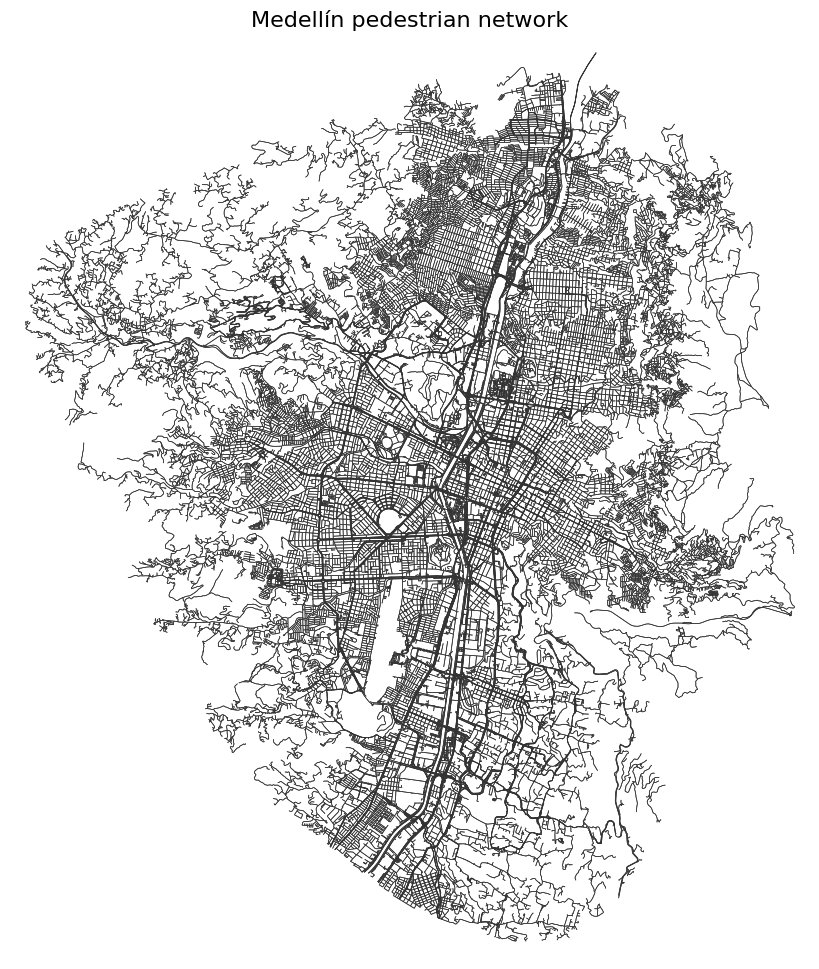

In [54]:
walk_graph_cache = DATA_DIR / 'medellin_walk.graphml'

if walk_graph_cache.exists():
    print(f'Loading cached walk network')
    Gu = ox.load_graphml(walk_graph_cache)
else:
    print('Building pedestrian network from OSM...')
    perim_wgs = gpd.GeoSeries([perim], crs=UTM_CRS).to_crs(WGS84).iloc[0]
    perim_buffered = perim_wgs.buffer(0.02)
    G = ox.graph_from_polygon(perim_buffered, network_type='walk', simplify=True)
    Gu = ox.convert.to_undirected(G)
    Gu = Gu.subgraph(max(nx.connected_components(Gu), key=len)).copy()
    ox.save_graphml(Gu, walk_graph_cache)

print(f'Walk network: {Gu.number_of_nodes():,} nodes, {Gu.number_of_edges():,} edges')


fig, ax = ox.plot_graph(
    Gu,
    figsize=(12, 12),
    bgcolor="white",
    node_size=0,
    edge_color="#333333",
    edge_linewidth=0.5,
    show=False,
    close=False,
)

ax.set_title("Medellín pedestrian network", fontsize=16)
plt.show()

In [55]:
# %%
print('Building sparse adjacency matrix...')
nodes = list(Gu.nodes())
node_idx = {n: i for i, n in enumerate(nodes)}

node_xy = np.array([[Gu.nodes[n]['x'], Gu.nodes[n]['y']] for n in nodes])
node_utm = gpd.GeoSeries([Point(x, y) for x, y in node_xy], crs=WGS84).to_crs(UTM_CRS)
node_coords_utm = np.c_[node_utm.x, node_utm.y]
tree = cKDTree(node_coords_utm)

# Build CSR matrix (collapse parallel edges)
best_edges = {}
for u, v, d in Gu.edges(data=True):
    i, j = node_idx[u], node_idx[v]
    key = (i, j) if i < j else (j, i)
    length_m = float(d.get('length', 0.0))
    time_min = length_m / WALK_M_PER_MIN
    if key not in best_edges or time_min < best_edges[key]:
        best_edges[key] = time_min

rows, cols, weights = [], [], []
for (i, j), t in best_edges.items():
    rows += [i, j]
    cols += [j, i]
    weights += [t, t]

A = sp.csr_matrix((weights, (rows, cols)), shape=(len(nodes), len(nodes)))
print(f'Adjacency matrix: {A.nnz} edges')

Building sparse adjacency matrix...
Adjacency matrix: 143383 edges


In [56]:
print('Snapping grid centroids...')
grid_coords_utm = np.c_[grid.centroid_utm.x, grid.centroid_utm.y]
_, grid_nodes = tree.query(grid_coords_utm)

print(f'Snapping {len(hospitals_gdf)} hospitals...')
hosp_coords_utm = np.c_[hospitals_gdf.geometry.x, hospitals_gdf.geometry.y]
_, hosp_nodes = tree.query(hosp_coords_utm)

# Multi-source Dijkstra
print('Running Dijkstra...')
unique_hosp_nodes = np.unique(hosp_nodes)
dist = dijkstra(A, directed=False, indices=unique_hosp_nodes, min_only=True)

walking_times = dist[grid_nodes]
walking_times = np.where(np.isfinite(walking_times), walking_times, SENTINEL)
grid['t_hospital'] = walking_times

cov_15 = (walking_times <= 15.0).sum()
cov_30 = (walking_times <= 30.0).sum()
print(f'\nWalking times computed:')
print(f'  Min: {np.nanmin(walking_times):.1f} min')
print(f'  Mean: {np.nanmean(walking_times):.1f} min')
print(f'  Median: {np.nanmedian(walking_times):.1f} min')
print(f'  Max: {np.nanmax(walking_times):.1f} min')
print(f'\nCoverage:')
print(f'  15 min: {cov_15:,} cells ({100*cov_15/len(grid):.1f}%)')
print(f'  30 min: {cov_30:,} cells ({100*cov_30/len(grid):.1f}%)')

Snapping grid centroids...
Snapping 223 hospitals...
Running Dijkstra...

Walking times computed:
  Min: 0.0 min
  Mean: 13.4 min
  Median: 9.7 min
  Max: 109.9 min

Coverage:
  15 min: 9,210 cells (70.0%)
  30 min: 12,254 cells (93.2%)


In [57]:
# %%
filtration_matrix = np.full((n_rows, n_cols), SENTINEL)
filtration_matrix[grid.row_idx.values, grid.col_idx.values] = grid['t_hospital'].values

print(f'Filtration matrix: {filtration_matrix.shape}')

Filtration matrix: (149, 130)


In [62]:
type(grid)

geopandas.geodataframe.GeoDataFrame

In [58]:
print('Computing persistent homology...')
cc = gudhi.CubicalComplex(
    dimensions=list(filtration_matrix.shape),
    top_dimensional_cells=filtration_matrix.flatten().tolist()
)
cc.compute_persistence()

persistence_pairs = cc.persistence()
h0_pairs = [(b, d) for dim, (b, d) in persistence_pairs if dim == 0]
h1_pairs = [(b, d) for dim, (b, d) in persistence_pairs if dim == 1]

h0_finite = [(b, d) for b, d in h0_pairs if d < SENTINEL]
h1_finite = [(b, d) for b, d in h1_pairs if d < SENTINEL]

print(f'\nH₀ (connected components):')
print(f'  Total: {len(h0_pairs)}, Finite: {len(h0_finite)}')
if h0_finite:
    print(f'  Mean pers: {np.mean([d-b for b,d in h0_finite]):.2f} min')
    print(f'  Max pers: {max(d-b for b,d in h0_finite):.2f} min')

print(f'\nH₁ (holes):')
print(f'  Total: {len(h1_pairs)}, Finite: {len(h1_finite)}')
if h1_finite:
    print(f'  Mean pers: {np.mean([d-b for b,d in h1_finite]):.2f} min')
    print(f'  Max pers: {max(d-b for b,d in h1_finite):.2f} min')

frag_15 = sum(1 for b, d in h0_pairs if b <= 15.0 < d)
print(f'\nAt 15-minute threshold:')
print(f'  Fragmentation: {frag_15}')
print(f'  H₁ features: {sum(1 for b, d in h1_pairs if b <= 15.0 < d)}')

Computing persistent homology...

H₀ (connected components):
  Total: 913, Finite: 897
  Mean pers: 2.84 min
  Max pers: 44.03 min

H₁ (holes):
  Total: 471, Finite: 422
  Mean pers: 3.63 min
  Max pers: 85.08 min

At 15-minute threshold:
  Fragmentation: 45
  H₁ features: 69


Saved: fig_hospitals_walking_time.png


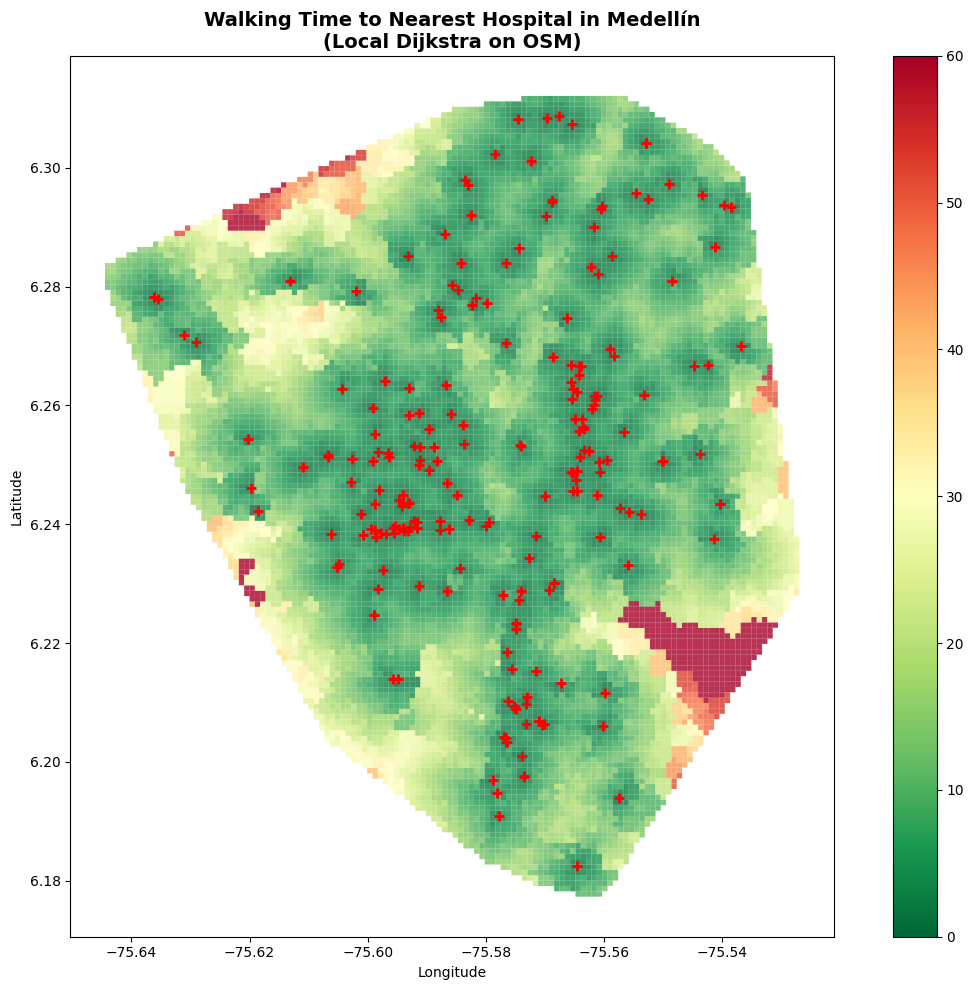

In [59]:
fig, ax = plt.subplots(figsize=(12, 10))
grid_plot = grid.copy().to_crs(WGS84)
grid_plot.plot(
    column='t_hospital',
    cmap='RdYlGn_r',
    ax=ax,
    legend=True,
    vmin=0,
    vmax=60,
    edgecolor='none',
    alpha=0.8
)
hospitals_gdf.to_crs(WGS84).plot(ax=ax, color='red', markersize=50, marker='+', linewidth=2)
ax.set_title('Walking Time to Nearest Hospital in Medellín\n(Local Dijkstra on OSM)', fontsize=14, weight='bold')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'fig_hospitals_walking_time.png', dpi=150, bbox_inches='tight')
print('Saved: fig_hospitals_walking_time.png')
plt.show()

Saved: fig_hospitals_persistence_diagram.png


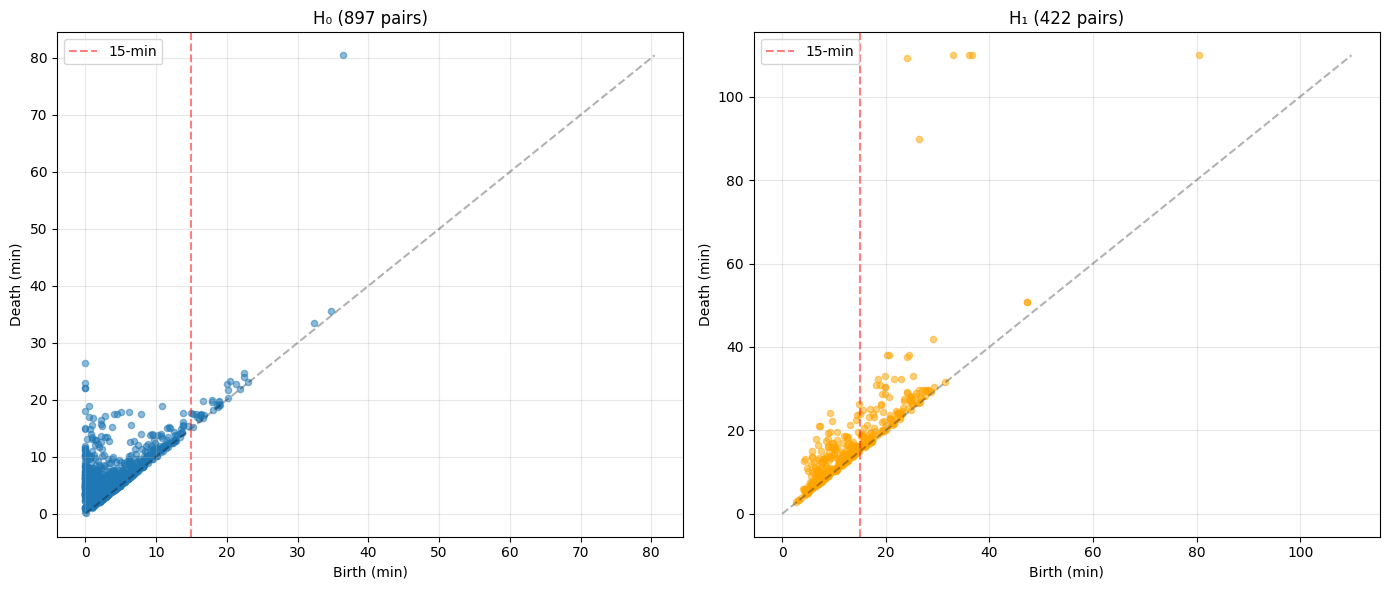

In [60]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

if h0_finite:
    h0_b = [b for b, d in h0_finite]
    h0_d = [d for b, d in h0_finite]
    ax1.scatter(h0_b, h0_d, alpha=0.5, s=20)
    max_val = max(max(h0_b + h0_d), 50)
    ax1.plot([0, max_val], [0, max_val], 'k--', alpha=0.3)
ax1.axvline(15, color='red', linestyle='--', alpha=0.5, label='15-min')
ax1.set_xlabel('Birth (min)')
ax1.set_ylabel('Death (min)')
ax1.set_title(f'H₀ ({len(h0_finite)} pairs)')
ax1.grid(True, alpha=0.3)
ax1.legend()

if h1_finite:
    h1_b = [b for b, d in h1_finite]
    h1_d = [d for b, d in h1_finite]
    ax2.scatter(h1_b, h1_d, alpha=0.5, color='orange', s=20)
    max_val = max(max(h1_b + h1_d), 50)
    ax2.plot([0, max_val], [0, max_val], 'k--', alpha=0.3)
ax2.axvline(15, color='red', linestyle='--', alpha=0.5, label='15-min')
ax2.set_xlabel('Birth (min)')
ax2.set_ylabel('Death (min)')
ax2.set_title(f'H₁ ({len(h1_finite)} pairs)')
ax2.grid(True, alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.savefig(RESULTS_DIR / 'fig_hospitals_persistence_diagram.png', dpi=150, bbox_inches='tight')
print('Saved: fig_hospitals_persistence_diagram.png')
plt.show()

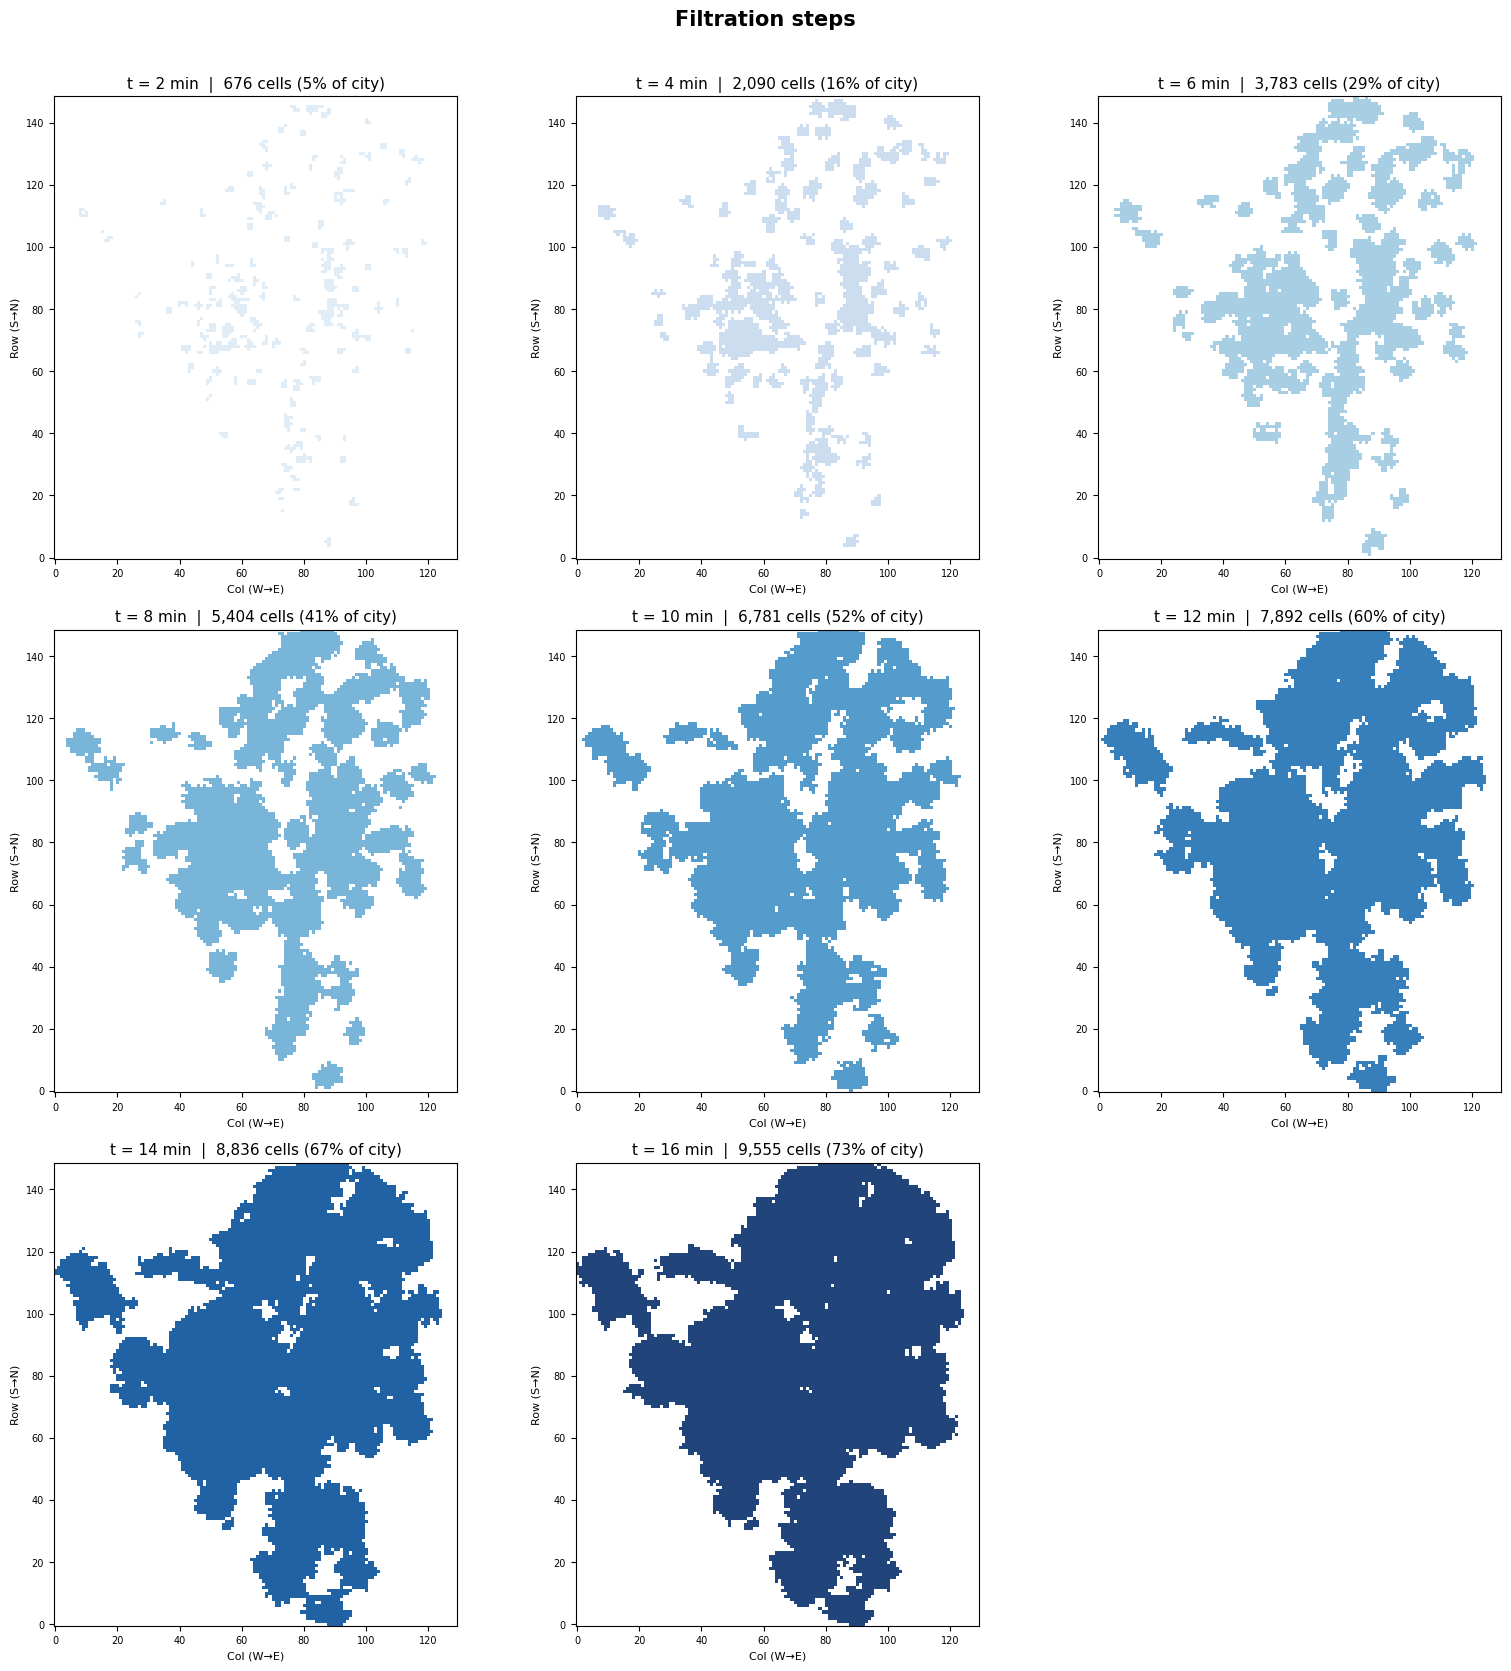

In [61]:
# ── Spatial maps of the sublevel sets at increasing thresholds ────────────────
THRESHOLDS = [2,4,6,8,10,12,14,16]
NCOLS = 3
NROWS = int(np.ceil(len(THRESHOLDS) / NCOLS))

fig, axes = plt.subplots(NROWS, NCOLS, figsize=(16, NROWS * 5.5))
axes = axes.flatten()

for i, t in enumerate(THRESHOLDS):
    ax = axes[i]

    # Binary mask: included at threshold t?
    included = filtration_matrix <= t
    disp = np.where(included, t, np.nan)

    ax.imshow(
        disp,
        origin='lower',
        cmap='Blues',
        vmin=0, vmax=max(THRESHOLDS),
        interpolation='nearest',
        alpha=0.9
    )

    pct = 100 * included.sum() / (filtration_matrix < SENTINEL).sum()
    ax.set_title(f't = {t} min  |  {included.sum():,} cells ({pct:.0f}% of city)', fontsize=11)
    ax.set_xlabel('Col (W→E)', fontsize=8)
    ax.set_ylabel('Row (S→N)', fontsize=8)
    ax.tick_params(labelsize=7)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

fig.suptitle(
    'Filtration steps',
    fontsize=15, fontweight='bold', y=1.01
)
plt.tight_layout()
plt.savefig(FIGS_DIR / 'fig05_filtration_snapshots.png', dpi=150, bbox_inches='tight')
plt.show()
